# Session 13 — Transformers beyond text

Every model in this course so far has read tokens of text. The same transformer block reads images once an image is cut into patches, and a model trained on images paired with captions can classify photos it was never trained to classify. We use CLIP ViT-B/32 on the 2,000 flower photos of the basic course's Session 9, with the same split, so its results compare directly with the MobileNetV2 model trained there.

**By the end of the session you should be able to:**

1. explain how a vision transformer turns an image into a sequence of tokens, and check that the patch embedding is one shared matrix;
2. classify images zero-shot with text prompts, and compare that with a linear classifier trained on a few labelled photos;
3. inspect attention maps and text search results, and say what they show and what they do not.

**To run it yourself** you need the packages from Session 7 plus Pillow and scikit-learn, the flower photos from the basic course (`~/.cache/ai_journey/flower_photos`, downloaded by its Session 9), and `openai/clip-vit-base-patch32` (about 600 MB, downloaded on first run). The notebook took about a minute on our laptop GPU. It also runs on a CPU, more slowly: computing the 2,000 image vectors is the slow step.

> **Callback · Basic Session 9.** These are the flower photos of basic Session 9. The zero-shot numbers are compared with the networks trained there.

In [1]:
import pathlib, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed
import torch, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from transformers import CLIPModel, CLIPProcessor
from transformers.utils import logging
from huggingface_hub.utils import logging as hub_logging
logging.set_verbosity_error(); hub_logging.set_verbosity_error(); set_seed(0)
# the same 2,000 photos and the same train/validation/test split as Session 9 of the basic course
root = pathlib.Path.home() / ".cache" / "ai_journey" / "flower_photos"  # downloaded by Session 9 of the basic course
all_files = sorted(root.glob("**/*.jpg")); classes = sorted({f.parent.name for f in all_files}); rng = np.random.default_rng(42); paths, labels = [], []
for k, name in enumerate(classes):
    files = [f for f in all_files if f.parent.name == name]; chosen = [files[i] for i in rng.permutation(len(files))[:400]]; paths += [str(f) for f in chosen]; labels += [k] * len(chosen)
paths, labels = np.array(paths), np.array(labels)
p_train, p_rest, y_train, y_rest = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=42)
p_val, p_test, y_val, y_test = train_test_split(p_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=42)
print(f"{len(all_files)} photos, {len(paths)} used; train {len(p_train)}, validation {len(p_val)}, test {len(p_test)}; classes {classes}")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32", attn_implementation="eager").to(DEVICE).eval(); proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32", use_fast=False)  # the Pillow-based image processor, so results do not depend on whether torchvision is installed
vc = model.config.vision_config
print(f"CLIP ViT-B/32: image encoder {sum(p.numel() for p in model.vision_model.parameters()) / 1e6:.0f}M parameters, text encoder {sum(p.numel() for p in model.text_model.parameters()) / 1e6:.0f}M; "
      f"images {vc.image_size}x{vc.image_size} cut into {vc.patch_size}x{vc.patch_size} patches = {(vc.image_size // vc.patch_size) ** 2} patches, {vc.num_hidden_layers} blocks of width {vc.hidden_size}")

3670 photos, 2000 used; train 1400, validation 300, test 300; classes ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


CLIP ViT-B/32: image encoder 87M parameters, text encoder 63M; images 224x224 cut into 32x32 patches = 49 patches, 12 blocks of width 768


## 1. Patches are tokens

CLIP's image encoder is a vision transformer (ViT): the same blocks as in Session 2, reading a sequence. The sequence is the image cut into a grid of 32 × 32 pixel patches, read row by row like words in a sentence.

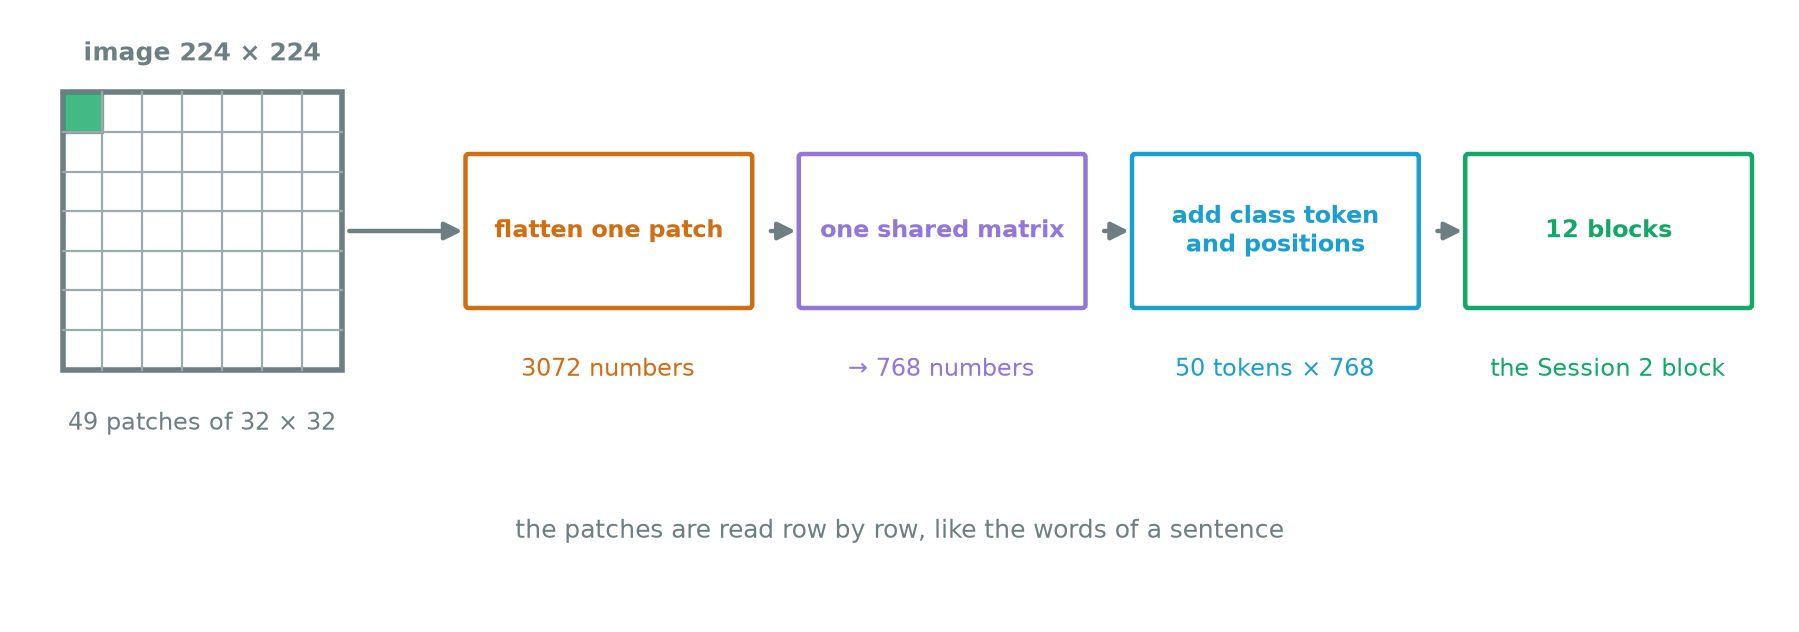

*Figure 13.1 — From an image to a sequence. The image is cut into 49 patches of 32 × 32; each is flattened to 3072 numbers and multiplied by one shared matrix to give 768 numbers; a class token and position vectors are added, giving 50 tokens that go through 12 blocks.*

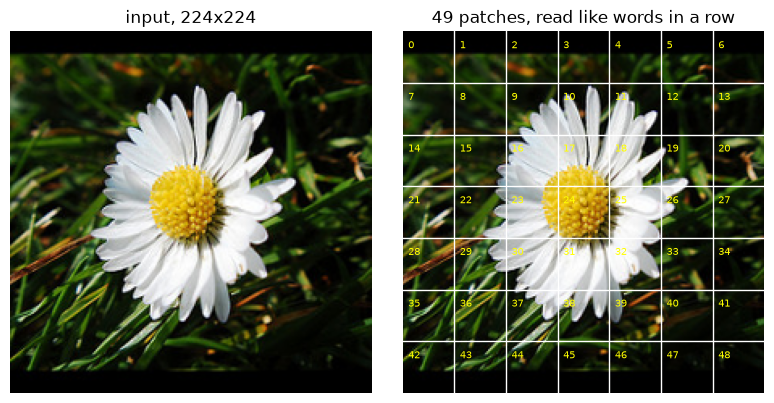

In [2]:
img = Image.open(p_test[0]).convert("RGB"); px = proc(images=img, return_tensors="pt")["pixel_values"].to(DEVICE)
P = vc.patch_size; n = vc.image_size // P
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
shown = (px[0].permute(1, 2, 0).cpu() * torch.tensor(proc.image_processor.image_std) + torch.tensor(proc.image_processor.image_mean)).clamp(0, 1)
ax[0].imshow(shown); ax[0].set_title(f"input, {vc.image_size}x{vc.image_size}"); ax[0].axis("off")
ax[1].imshow(shown); [ax[1].axhline(i * P - 0.5, color="w", lw=1) for i in range(1, n)]; [ax[1].axvline(i * P - 0.5, color="w", lw=1) for i in range(1, n)]
for i in range(n * n): ax[1].text((i % n) * P + 3, (i // n) * P + 10, str(i), color="yellow", fontsize=7)
ax[1].set_title(f"{n * n} patches, read like words in a row"); ax[1].axis("off"); plt.tight_layout(); plt.show()

Each patch is flattened into 3,072 numbers and multiplied by one shared matrix, giving a 768-number vector: the image's version of a token embedding. The library writes this as a convolution with a stride equal to the patch size. The next cell checks that the two are the same computation.

In [3]:
emb = model.vision_model.embeddings
with torch.no_grad():
    x64, w64 = px.double().cpu(), emb.patch_embedding.weight.double().cpu()            # float64 on the CPU, so that rounding does not hide the comparison
    conv = F.conv2d(x64, w64, stride=P).flatten(2).transpose(1, 2)                   # the library's way: a convolution with stride = patch size
    patches = x64.unfold(2, P, P).unfold(3, P, P).permute(0, 2, 3, 1, 4, 5).reshape(1, n * n, 3 * P * P)      # cut out the patches and flatten each one
    by_hand = patches @ w64.reshape(vc.hidden_size, -1).T
    tokens = emb(px)
print(f"each patch is {3 * P * P} numbers (3 colours x {P} x {P}); one shared matrix turns it into a {vc.hidden_size}-number vector")
print(f"convolution vs flatten-and-multiply: largest difference {(conv - by_hand).abs().max().item():.1e}")
print(f"the sequence the transformer reads: {tuple(tokens.shape)} = 1 class token + {n * n} patch tokens, each with a learned position vector added")
print("one encoder block:", model.vision_model.encoder.layers[0])

each patch is 3072 numbers (3 colours x 32 x 32); one shared matrix turns it into a 768-number vector
convolution vs flatten-and-multiply: largest difference 0.0e+00
the sequence the transformer reads: (1, 50, 768) = 1 class token + 49 patch tokens, each with a learned position vector added
one encoder block: CLIPEncoderLayer(
  (self_attn): CLIPAttention(
    (k_proj): Linear(in_features=768, out_features=768, bias=True)
    (v_proj): Linear(in_features=768, out_features=768, bias=True)
    (q_proj): Linear(in_features=768, out_features=768, bias=True)
    (out_proj): Linear(in_features=768, out_features=768, bias=True)
  )
  (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): CLIPMLP(
    (activation_fn): QuickGELUActivation()
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
  )
  (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
)


The convolution and the flatten-and-multiply version agree exactly (largest difference 0.0 in float64). A class token is added at the front and a learned position vector is added to every token, so the transformer reads 50 tokens of width 768. From here on the block printed above is the familiar one: attention, layer norms and an MLP. Nothing in it knows it is looking at an image; only the first step and the training data differ.

## 2. Classifying without training

CLIP was trained to match images with their captions: an image encoder and a text encoder each produce a 512-number vector, and matching pairs should point the same way. To classify a photo, we write one text prompt per class, encode them, and pick the class whose text vector is closest to the photo's vector. No flower photo is used for training.

We try three prompts and an average of five.

> **Pause:** which will work best: the bare class name ("tulip"), "a photo of a tulip.", or "a photo of a tulip, a type of flower."?
>
> - **A.** The bare class name, "tulip": nothing else to confuse the encoder.
> - **B.** "a photo of a tulip.": it looks like a caption.
> - **C.** "a photo of a tulip, a type of flower.": it also names the domain.
> - **D.** All three within a point of each other: the word "tulip" is what matters.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** The class name alone scores 0.920, "a photo of a ..." 0.940 and the version that names the domain 0.973: a five-point spread, all from wording.

</details>

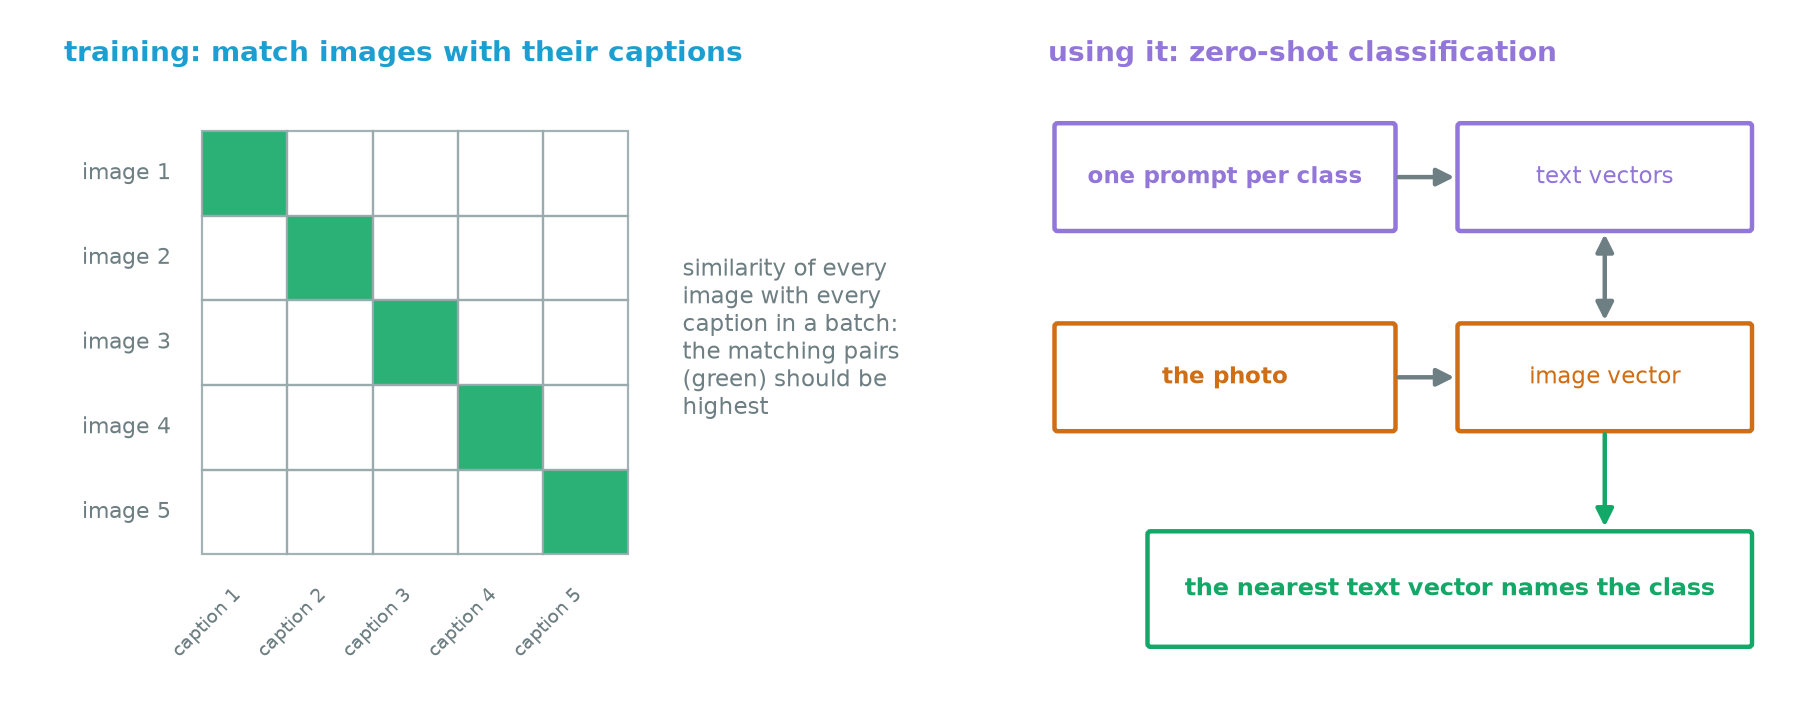

*Figure 13.2 — How CLIP is trained and how we use it. In training, every image in a batch is compared with every caption and the matching pairs on the diagonal should score highest. For zero-shot classification we write one prompt per class, encode them, encode the photo, and the nearest text vector names the class.*

In [4]:
@torch.no_grad()
def image_features(ps, batch=64):
    out = []
    for i in range(0, len(ps), batch):
        px = proc(images=[Image.open(p).convert("RGB") for p in ps[i:i + batch]], return_tensors="pt")["pixel_values"].to(DEVICE)
        out.append(F.normalize(model.visual_projection(model.vision_model(pixel_values=px).pooler_output), dim=-1).cpu())
    return torch.cat(out)
@torch.no_grad()
def text_features(texts):
    enc = proc(text=texts, return_tensors="pt", padding=True).to(DEVICE)
    return F.normalize(model.text_projection(model.text_model(**enc).pooler_output), dim=-1).cpu()
t0 = time.perf_counter(); X = {"train": image_features(list(p_train)), "val": image_features(list(p_val)), "test": image_features(list(p_test))}
print(f"image vectors for {len(paths)} photos in {time.perf_counter() - t0:.0f} s; each is {X['test'].shape[1]} numbers")
names = {"daisy": "daisy", "dandelion": "dandelion", "roses": "rose", "sunflowers": "sunflower", "tulips": "tulip"}
TEMPLATES = {"class name only": "{}", "a photo of a {}.": "a photo of a {}.", "a photo of a {}, a type of flower.": "a photo of a {}, a type of flower."}
rows, zs = [], {}
for label, tpl in TEMPLATES.items():
    T = text_features([tpl.format(names[c]) for c in classes]); pred = (X["test"] @ T.T).argmax(1).numpy(); zs[label] = T
    rows.append({"text prompt": label, "test accuracy (300 photos)": (pred == y_test).mean()})
ens = F.normalize(sum(text_features([tpl.format(names[c]) for c in classes]) for tpl in ["a photo of a {}.", "a close-up photo of a {}.", "a photo of a {}, a type of flower.", "a bright photo of a {}.", "a cropped photo of a {}."]), dim=-1)
rows.append({"text prompt": "average of 5 prompts", "test accuracy (300 photos)": ((X["test"] @ ens.T).argmax(1).numpy() == y_test).mean()})
display(pd.DataFrame(rows).round(3))
print("for comparison, Session 9 of the basic course, MobileNetV2 with ImageNet weights trained on these 1,400 photos, on the same 300: frozen features with a trained head 0.850, fine-tuned 0.883")

image vectors for 2000 photos in 19 s; each is 512 numbers


,text prompt,test accuracy (300 photos)
0,class name only,0.920
1,a photo of a {}.,0.940
2,"a photo of a {}, a type of flower.",0.973
3,average of 5 prompts,0.970


for comparison, Session 9 of the basic course, MobileNetV2 with ImageNet weights trained on these 1,400 photos, on the same 300: frozen features with a trained head 0.850, fine-tuned 0.883


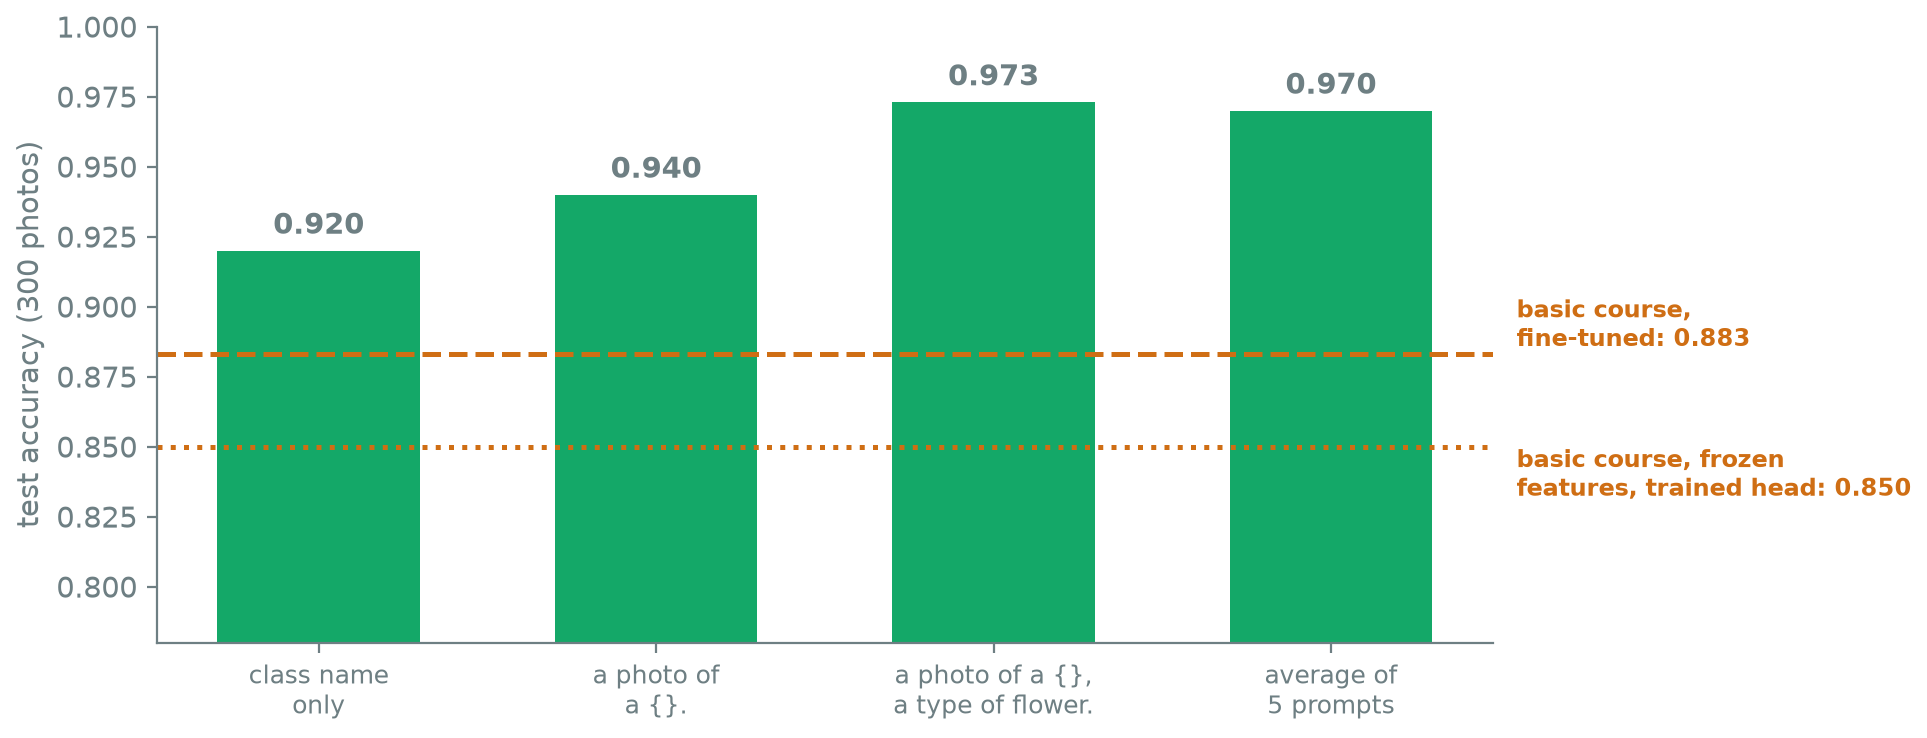

*Figure 13.3 — Zero-shot test accuracy by prompt wording: 0.920 for the class name alone, 0.940 for a photo of a flower, 0.973 with the domain named and 0.970 for an average of five prompts. The dotted and dashed lines are the basic course's trained models on the same 300 photos, 0.850 and 0.883.*

The bare class name scores 0.920, "a photo of a ..." 0.940, and "a photo of a ..., a type of flower." 0.973. The captions CLIP was trained on are sentences, so a prompt that looks like a caption works better, and naming the domain helps further. Averaging five prompts gives 0.970, as good as the best single one.

For comparison, the basic course's Session 9 models, MobileNetV2 with ImageNet weights trained on the 1,400 training photos, score 0.850 on the same 300 test photos with the network frozen and only a new head trained, and 0.883 after fine-tuning part of the network. CLIP beats both without seeing a single labelled flower.

predicted,daisy,dandelion,roses,sunflowers,tulips
true,,,,,
daisy,60,0,0,0,0
dandelion,0,60,0,0,0
roses,1,1,55,0,3
sunflowers,0,1,0,59,0
tulips,0,0,2,0,58


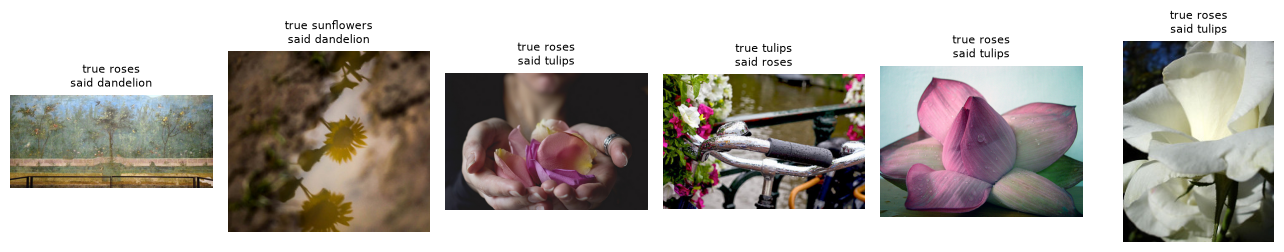

In [5]:
T = zs["a photo of a {}, a type of flower."]; pred = (X["test"] @ T.T).argmax(1).numpy()
cm = pd.crosstab(pd.Series([classes[i] for i in y_test], name="true"), pd.Series([classes[i] for i in pred], name="predicted")); display(cm)
wrong = np.where(pred != y_test)[0][:6]
fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.6))
for ax, i in zip(axes, wrong): ax.imshow(Image.open(p_test[i]).convert("RGB")); ax.set_title(f"true {classes[y_test[i]]}\nsaid {classes[pred[i]]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

With the best prompt, CLIP gets 8 of the 300 photos wrong; daisies and dandelions are all right. Look at the mistakes before blaming the model. Two photos labelled "roses" are a fresco of a garden with no visible roses and what appears to be a lotus flower. One "tulips" photo shows a bicycle with flowers in the background, and one "sunflowers" photo is a few blurred flower heads. A test set of 300 photos contains its own errors, and at 0.973 they are a large share of what is left.

## 3. A few labelled photos

Zero-shot needs no training photos at all. The usual alternative is a **linear probe**: keep CLIP frozen and train a logistic regression on its image vectors. We train it with 1 to 280 photos per class, drawing the training photos 5 times for each size.

> **Pause:** how many labelled photos per class will the probe need to match zero-shot?
>
> - **A.** One or two: CLIP's vectors already separate the flowers.
> - **B.** About 10.
> - **C.** About 50.
> - **D.** It never matches it, however many photos it gets.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**C.** With 1 photo per class the probe scores 0.651 and with 10 it scores 0.945. From 50 per class it reaches 0.970, and zero-shot scores 0.973: a difference of one photo out of 300.

</details>

,training photos per class,test accuracy,spread over 5 draws
0,1,0.651,0.092
1,2,0.831,0.050
2,5,0.888,0.014
3,10,0.945,0.003
4,20,0.954,0.011
5,50,0.970,0.005
6,280,0.970,NaN


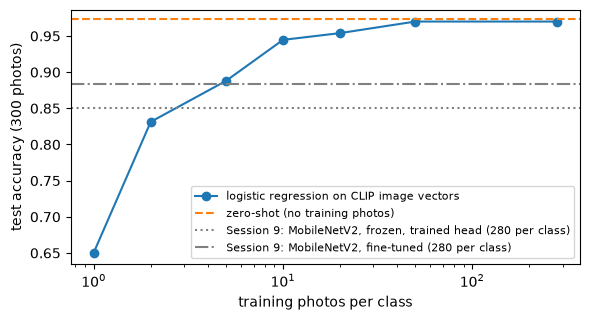

In [6]:
rows = []
for k in (1, 2, 5, 10, 20, 50, 280):
    accs = []
    for rep in range(5 if k < 280 else 1):
        g = np.random.default_rng(rep); idx = np.concatenate([g.choice(np.where(y_train == c)[0], k, replace=False) for c in range(5)])
        clf = LogisticRegression(C=10, max_iter=2000).fit(X["train"][idx].numpy(), y_train[idx]); accs.append(clf.score(X["test"].numpy(), y_test))
    rows.append({"training photos per class": k, "test accuracy": np.mean(accs), "spread over 5 draws": np.std(accs) if k < 280 else np.nan})
probe = pd.DataFrame(rows); display(probe.round(3))
plt.figure(figsize=(6, 3.3)); plt.semilogx(probe["training photos per class"], probe["test accuracy"], "o-", label="logistic regression on CLIP image vectors")
plt.axhline((pred == y_test).mean(), color="C1", ls="--", label="zero-shot (no training photos)")
plt.axhline(0.850, color="grey", ls=":", label="Session 9: MobileNetV2, frozen, trained head (280 per class)")
plt.axhline(0.883, color="grey", ls="-.", label="Session 9: MobileNetV2, fine-tuned (280 per class)")
plt.xlabel("training photos per class"); plt.ylabel("test accuracy (300 photos)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

With one photo per class the probe scores 0.651, and the result depends heavily on which photo you draw (spread 0.092). With 10 per class it reaches 0.945, and with 50 it reaches 0.970, the same as with all 280. It never passes zero-shot (0.973). On 300 test photos one photo is worth 0.003, so 0.970 and 0.973 differ by a single photo: from 50 photos per class up, the probe and zero-shot are equally good.

Both are far above the basic course's 0.850 (frozen) and 0.883 (fine-tuned), and with only 5 photos per class the probe (0.888) already matches the fine-tuned MobileNetV2 trained on 280. The difference is the encoder: CLIP's vectors already separate these flowers, so even a simple classifier on top does well. For classes that a caption rarely describes, such as a factory's own part numbers, zero-shot has nothing to work with and a probe or fine-tuning is needed.

## 4. Where does the class token look?

The class token collects the image's summary, and its attention over the 49 patches is often shown as an explanation of what the model "looks at". We plot it, averaged over the 12 heads, in the first and the last block for five test photos.

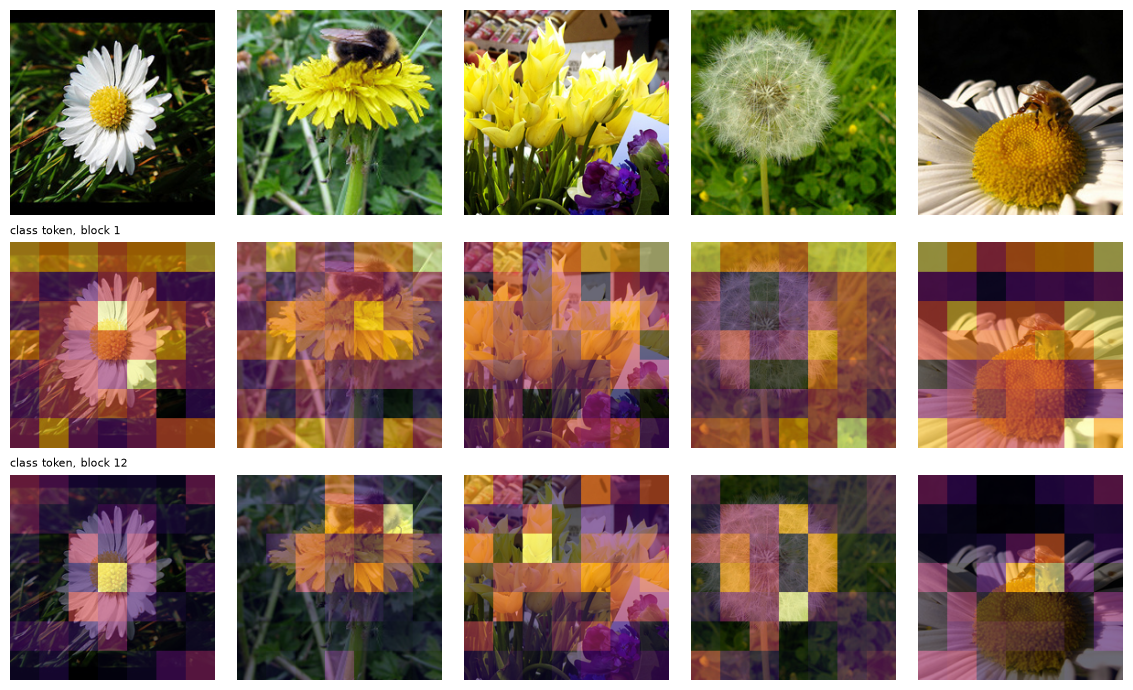

In [7]:
@torch.no_grad()
def cls_attention(path):
    px = proc(images=Image.open(path).convert("RGB"), return_tensors="pt")["pixel_values"].to(DEVICE)
    att = model.vision_model(pixel_values=px, output_attentions=True).attentions                 # one (1, heads, 50, 50) tensor per block
    return [a[0, :, 0, 1:].mean(0).reshape(n, n).cpu() for a in att], px
show = [p_test[i] for i in range(0, 300, 60)]
fig, axes = plt.subplots(3, len(show), figsize=(2.3 * len(show), 7))
for j, path in enumerate(show):
    maps, px = cls_attention(path); im = (px[0].permute(1, 2, 0).cpu() * torch.tensor(proc.image_processor.image_std) + torch.tensor(proc.image_processor.image_mean)).clamp(0, 1)
    axes[0, j].imshow(im); axes[0, j].axis("off")
    for r, (layer, a) in enumerate(((1, maps[0]), (len(maps), maps[-1]))):
        axes[r + 1, j].imshow(im); axes[r + 1, j].imshow(F.interpolate(a[None, None], size=im.shape[:2], mode="nearest")[0, 0], alpha=0.6, cmap="inferno"); axes[r + 1, j].axis("off")
        if j == 0: axes[r + 1, j].set_title(f"class token, block {layer}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In block 1 the maps are a patchwork with no visible relation to the flowers. In block 12 the attention concentrates on a handful of patches: on the daisy's centre in the first photo, but on scattered patches of petals, edges and background in the others. These maps do not outline the object, and they are not a reliable account of what the model uses. Going deeper describes better methods.

## 5. Searching photos with text

Because images and text share one vector space, any sentence can be used as a query: encode it, and rank the photos by how close their vectors are. We search the 300 test photos with five queries and show the top four for each, with their similarity.

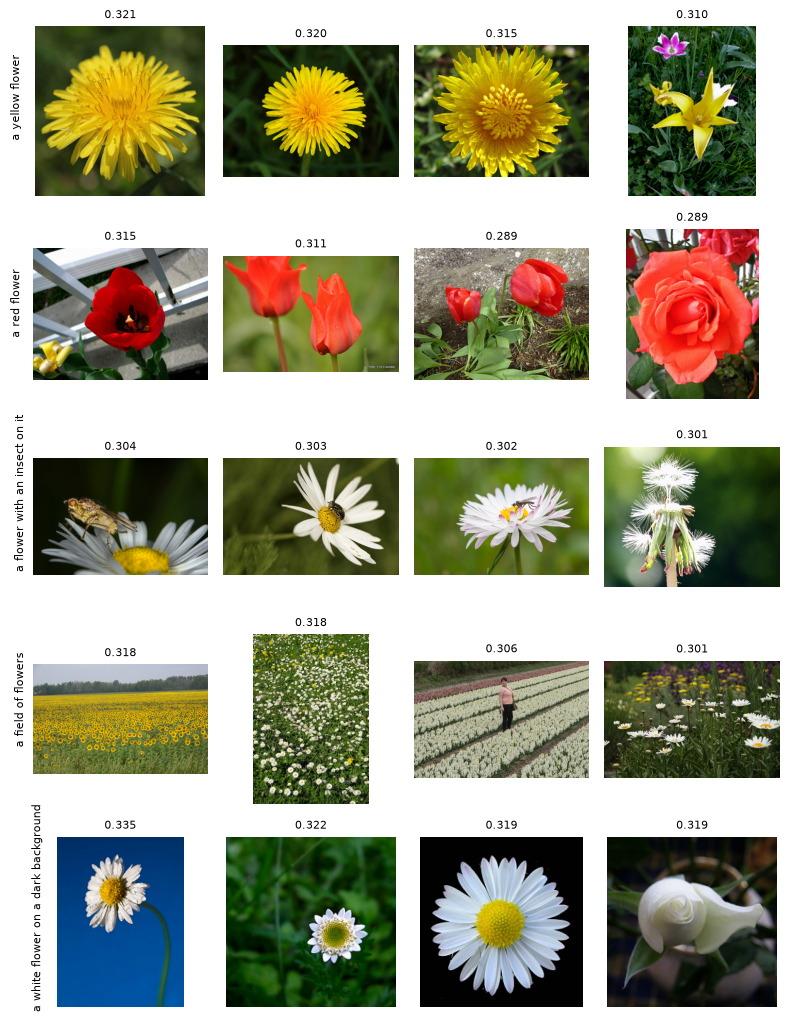

In [8]:
queries = ["a yellow flower", "a red flower", "a flower with an insect on it", "a field of flowers", "a white flower on a dark background"]
Q = text_features(queries); sims = X["test"] @ Q.T
fig, axes = plt.subplots(len(queries), 4, figsize=(8, 2.1 * len(queries)))
for r, q in enumerate(queries):
    top = sims[:, r].topk(4).indices
    for c, i in enumerate(top): axes[r, c].imshow(Image.open(p_test[i]).convert("RGB")); axes[r, c].set_title(f"{sims[i, r]:.3f}", fontsize=8); axes[r, c].axis("off")
    axes[r, 0].text(-20, 100, q, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.show()

"A yellow flower" returns three dandelions and a yellow tulip, and "a red flower" three photos of red tulips and a red rose: colour is easy. Three of the four results for "a flower with an insect on it" show an insect; the fourth, a white wispy flower, does not. "A field of flowers" returns four fields of different flowers. "A white flower on a dark background" returns four white flowers, but only two of the backgrounds are dark: CLIP matched the flower better than the composition. The similarities are all between 0.289 and 0.335; the numbers are only meaningful for ranking within one query.

## What to take away

- A vision transformer is the text transformer with a different first step: cut the image into patches, multiply each by one shared matrix, add positions.
- A model trained on images with captions can classify by comparing a photo with text prompts. Here zero-shot scores 0.973 against 0.850 and 0.883 for the basic course's trained models, and the wording of the prompt moves it by 5 points.
- A linear probe on the same vectors needs about 50 labelled photos per class to match zero-shot on these classes.
- Read the mistakes: some are errors in the labels. And treat attention maps as a picture of attention, not as an explanation.

---

# Going deeper

Reading for after the session.

## Vision transformers and CLIP

Dosovitskiy et al. (2021), *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*, introduced the vision transformer: patches, a class token, learned positions, and otherwise a standard transformer encoder. Radford et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision*, trained CLIP on 400 million image-caption pairs from the web with a contrastive loss: in each batch, every image should match its own caption and not the others. The model here, ViT-B/32, uses 32-pixel patches; versions with 16- or 14-pixel patches read more tokens per image and are more accurate and slower.

## Could CLIP have seen these photos?

The flower photos were collected from the web, and CLIP's training data came from the web. Some of the test photos, or near copies, could have been in its training data. Session 10's warning applies: a strong zero-shot score is evidence of ability only if the test data was unseen, and that was not checked here.

## Better explanations than raw attention

The class token's attention in one block ignores everything that happened in earlier blocks and in the MLPs. **Attention rollout** multiplies the attention maps of all blocks (adding the residual connection) to follow information from the input to the class token. Gradient-based methods ask instead how much the output changes when a patch changes. Darcet et al. (2024), *Vision Transformers Need Registers*, describe large ViTs that put high attention on a few background patches which store global information rather than content of that patch, and add extra "register" tokens to give the model somewhere else to put it. Whatever the method, check an explanation against an intervention, as Session 1 did by removing heads.

## From here to multimodal language models

Models that read images and answer in text usually take an image encoder like this one, map its patch vectors into the language model's embedding space with a small learned layer, and feed them to the language model as if they were tokens. Everything in Sessions 6 to 10 then applies: instruction tuning, retrieval, serving costs (an image costs as many tokens as it has patches) and evaluation.

## Changes from the earlier version of the course

The earlier advanced course had no session on images. This session is new; it reuses the basic course's flower photos and split so that the results can be compared with its Session 9.